In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Pitch

In [32]:
# Load data
pitch_data = pd.read_csv("output_pitch/IDP_pitch.csv")

In [33]:
pitch_data.head()

,Instrument,Models,f0_PYIN_W,df0_PYIN_W,f0_CREPE_W,df0_CREPE_W,f0_PYIN_K,df0_PYIN_K,f0_CREPE_K,df0_CREPE_K,f0_PYIN_J,df0_PYIN_J,f0_CREPE_J,df0_CREPE_J
0,Guitar,lyria,0.000095,0.000028,0.000107,0.000067,0.1589,0.00560,0.1772,0.003891,0.03570,0.000793,0.04435,0.000811
1,Guitar,suno,0.000149,0.000059,0.000084,0.000091,0.1524,0.00557,0.2700,0.006490,0.03371,0.001144,0.06363,0.001646
2,Guitar,musicgen,0.000140,0.000052,0.000085,0.000100,0.3798,0.00618,0.4050,0.007682,0.03959,0.001651,0.07326,0.001496
3,Guitar,mustango,0.000105,0.000097,0.000127,0.000290,0.4384,0.01221,0.3487,0.023750,0.08862,0.003430,0.06677,0.005902
4,Violin,lyria,0.000093,0.000125,0.000070,0.000156,0.2389,0.00789,0.1872,0.007614,0.04750,0.001809,0.04052,0.001794


In [34]:
# Columns (adjust if needed)
f0_cols = [
    "f0_PYIN_W", "f0_CREPE_W",
    "f0_PYIN_K", "f0_CREPE_K",
    "f0_PYIN_J", "f0_CREPE_J"
]

df0_cols = [
    "df0_PYIN_W", "df0_CREPE_W",
    "df0_PYIN_K", "df0_CREPE_K",
    "df0_PYIN_J", "df0_CREPE_J"
]

all_metric_cols = f0_cols + df0_cols

In [35]:
pitch_data_norm = pitch_data.copy()
for col in all_metric_cols:
    min_val = pitch_data[col].min()
    max_val = pitch_data[col].max()
    
    if max_val - min_val > 0:
        pitch_data_norm[col] = (pitch_data[col] - min_val) / (max_val - min_val)
    else:
        pitch_data_norm[col] = 0.0  # edge case

In [36]:
# ---- Aggregate scores ----
pitch_data_norm["f0_score"] = pitch_data_norm[f0_cols].mean(axis=1)
pitch_data_norm["df0_score"] = pitch_data_norm[df0_cols].mean(axis=1)

In [37]:
pitch_data_norm

,Instrument,Models,f0_PYIN_W,df0_PYIN_W,f0_CREPE_W,df0_CREPE_W,f0_PYIN_K,df0_PYIN_K,f0_CREPE_K,df0_CREPE_K,f0_PYIN_J,df0_PYIN_J,f0_CREPE_J,df0_CREPE_J,f0_score,df0_score
0,Guitar,lyria,0.056431,0.006538,0.347181,0.000000,0.007701,0.011446,0.000000,0.000000,0.015467,0.000000,0.060107,0.000000,0.081148,0.002997
1,Guitar,suno,0.256138,0.087866,0.174332,0.107830,0.000000,0.010786,0.125728,0.090090,0.000000,0.037714,0.199898,0.164015,0.126016,0.083050
2,Guitar,musicgen,0.223159,0.070084,0.186202,0.149888,0.269431,0.024213,0.308630,0.131408,0.045702,0.092189,0.269722,0.134551,0.217141,0.100389
3,Guitar,mustango,0.094907,0.187762,0.495549,1.000000,0.338863,0.156945,0.232353,0.688377,0.426784,0.283335,0.222665,1.000000,0.301853,0.552736
4,Violin,lyria,0.049835,0.259937,0.074184,0.400447,0.102488,0.061853,0.013548,0.129051,0.107182,0.109165,0.032338,0.193086,0.063262,0.192257
5,Violin,suno,0.432026,0.026151,0.144659,0.794183,0.131517,0.013647,0.011110,0.346944,0.108892,0.004728,0.019432,0.547633,0.141272,0.288881
6,Violin,musicgen,0.494320,0.283473,0.458457,0.044295,0.387085,0.316531,0.407397,0.141183,0.647210,0.415709,0.478031,0.172854,0.478750,0.229008
7,Violin,mustango,0.164529,0.182270,0.985163,0.248322,0.836611,0.120625,1.000000,0.644355,0.816882,0.211346,0.579249,0.563151,0.730406,0.328345
8,Sitar,lyria,0.461341,0.114278,0.910979,0.046085,0.215521,0.084085,0.089961,0.192658,0.365382,0.087998,0.150522,0.138087,0.365618,0.110532
9,Sitar,suno,0.523635,0.354079,0.525223,0.243848,0.458294,0.162228,0.805717,0.291483,0.697730,0.156871,1.000000,0.339815,0.668433,0.258054


### Timbre

In [38]:
# Load data
timbre_data = pd.read_csv("output_timbre/IDP_timbre.csv")

In [39]:
timbre_data["f0"] = pitch_data_norm["f0_score"]
timbre_data["df0"] = pitch_data_norm["df0_score"]

In [40]:
timbre_data

,Instrument,Models,Envelope,Centroid,Rolloff,Flux,HNR,f0,df0
0,Guitar,lyria,9.690,222.378,470.373,0.002940,0.5850,0.081148,0.002997
1,Guitar,suno,19.820,476.470,1079.470,0.005320,2.7000,0.126016,0.083050
2,Guitar,musicgen,10.784,156.006,427.464,0.003110,2.0750,0.217141,0.100389
3,Guitar,mustango,12.817,190.605,254.186,0.007410,2.2000,0.301853,0.552736
4,Violin,lyria,15.340,172.297,491.274,0.010300,1.0230,0.063262,0.192257
5,Violin,suno,14.740,174.110,223.160,0.003350,1.0760,0.141272,0.288881
6,Violin,musicgen,9.525,221.600,330.599,0.005810,2.1090,0.478750,0.229008
7,Violin,mustango,11.562,228.066,364.804,0.008510,0.9250,0.730406,0.328345
8,Sitar,lyria,11.020,355.591,729.088,0.001490,1.8420,0.365618,0.110532
9,Sitar,suno,20.850,846.830,1884.060,0.014800,3.2830,0.668433,0.258054


In [41]:
# timbre_data.to_csv("IDP_spider.csv", index=False)

### Spider Plot

In [42]:
metric_cols = [
    "Envelope", "Centroid", "Rolloff", "Flux", "HNR", "f0", "df0"
]

In [43]:
timbre_data_norm = timbre_data.copy()
for col in metric_cols:
    min_val = timbre_data[col].min()
    max_val = timbre_data[col].max()
    timbre_data_norm[col] = (timbre_data[col] - min_val) / (max_val - min_val + 1e-8)
    timbre_data_norm[col] = 1 - timbre_data_norm[col]  # invert (lower distance = better)

In [44]:
timbre_data_norm

,Instrument,Models,Envelope,Centroid,Rolloff,Flux,HNR,f0,df0
0,Guitar,lyria,8.185419e-01,8.454765e-01,8.502920e-01,8.656935e-01,9.383729e-01,9.771267e-01,1.000000e+00
1,Guitar,suno,7.554643e-02,5.014487e-01,4.839377e-01,6.919710e-01,4.695190e-01,9.197460e-01,8.868468e-01
2,Guitar,musicgen,7.383013e-01,9.353408e-01,8.761005e-01,8.532848e-01,6.080692e-01,8.032091e-01,8.623386e-01
3,Guitar,mustango,5.891888e-01,8.884955e-01,9.803223e-01,5.394164e-01,5.803591e-01,6.948725e-01,2.229526e-01
4,Violin,lyria,4.041367e-01,9.132836e-01,8.377207e-01,3.284676e-01,8.412769e-01,1.000000e+00,7.324849e-01
5,Violin,suno,4.481443e-01,9.108289e-01,9.989835e-01,8.357665e-01,8.295278e-01,9.002352e-01,5.959079e-01
6,Violin,musicgen,8.306440e-01,8.465298e-01,9.343620e-01,6.562046e-01,6.005320e-01,4.686442e-01,6.805382e-01
7,Violin,mustango,6.812381e-01,8.377752e-01,9.137887e-01,4.591245e-01,8.630016e-01,1.468087e-01,5.401265e-01
8,Sitar,lyria,7.209916e-01,6.651128e-01,6.946824e-01,9.715329e-01,6.597207e-01,6.133262e-01,8.480014e-01
9,Sitar,suno,7.334605e-10,1.353950e-11,6.014633e-12,7.299265e-07,3.402793e-01,2.260636e-01,6.394813e-01


In [45]:
timbre_data_norm_rounded = timbre_data_norm.copy()
timbre_data_norm_rounded[metric_cols] = timbre_data_norm[metric_cols].round(3)
timbre_data_norm_rounded

,Instrument,Models,Envelope,Centroid,Rolloff,Flux,HNR,f0,df0
0,Guitar,lyria,0.819,0.845,0.850,0.866,0.938,0.977,1.000
1,Guitar,suno,0.076,0.501,0.484,0.692,0.470,0.920,0.887
2,Guitar,musicgen,0.738,0.935,0.876,0.853,0.608,0.803,0.862
3,Guitar,mustango,0.589,0.888,0.980,0.539,0.580,0.695,0.223
4,Violin,lyria,0.404,0.913,0.838,0.328,0.841,1.000,0.732
5,Violin,suno,0.448,0.911,0.999,0.836,0.830,0.900,0.596
6,Violin,musicgen,0.831,0.847,0.934,0.656,0.601,0.469,0.681
7,Violin,mustango,0.681,0.838,0.914,0.459,0.863,0.147,0.540
8,Sitar,lyria,0.721,0.665,0.695,0.972,0.660,0.613,0.848
9,Sitar,suno,0.000,0.000,0.000,0.000,0.340,0.226,0.639


### single plots

In [46]:
# def plot_instrument(df, instrument):
#     subset = df[df["Instrument"] == instrument]
#     models = subset["Models"].values
    
#     num_metrics = len(metric_cols)
#     angles = np.linspace(0, 2*np.pi, num_metrics, endpoint=False).tolist()
#     angles += angles[:1]  # close loop

#     fig, ax = plt.subplots(figsize=(6,6), subplot_kw=dict(polar=True))

#     for _, row in subset.iterrows():
#         values = row[metric_cols].tolist()
#         values += values[:1]

#         ax.plot(angles, values, label=row["Models"])
#         ax.fill(angles, values, alpha=0.1)

#     ax.set_xticks(angles[:-1])
#     ax.set_xticklabels(metric_cols)

#     ax.set_title(instrument)
#     ax.set_ylim(0, 1)
#     ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))

#     plt.show()

In [47]:
# # ---- Generate plots for all instruments ----
# for inst in timbre_data_norm["Instrument"].unique():
#     plot_instrument(timbre_data_norm, inst)

### subplot

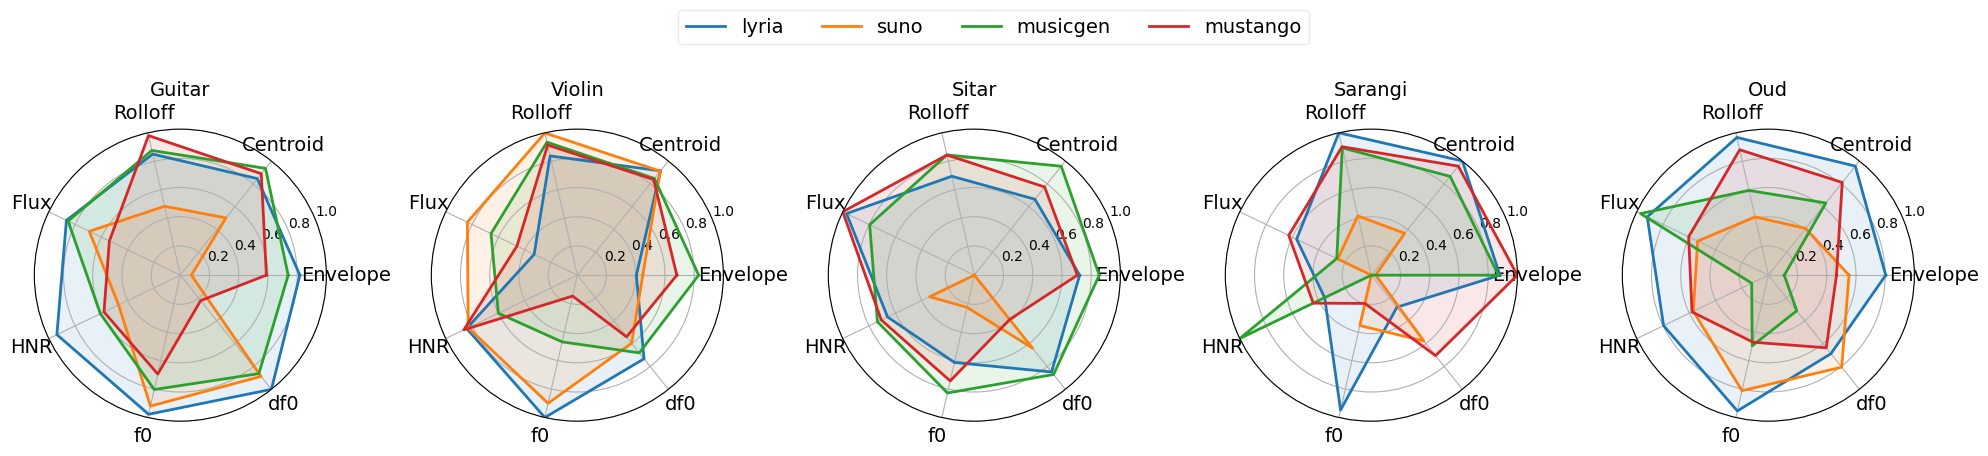

In [48]:
# ---- Radar setup ----
num_metrics = len(metric_cols)
angles = np.linspace(0, 2*np.pi, num_metrics, endpoint=False).tolist()
angles += angles[:1]

instruments = timbre_data_norm["Instrument"].unique()
models = timbre_data_norm["Models"].unique()

# ---- Create subplots ----
fig, axes = plt.subplots(1, len(instruments), figsize=(20, 5), subplot_kw=dict(polar=True))
axes = axes.flatten()

legend_handles = []

for i, inst in enumerate(instruments):
    ax = axes[i]
    subset = timbre_data_norm[timbre_data_norm["Instrument"] == inst]

    for j, (_, row) in enumerate(subset.iterrows()):
        values = row[metric_cols].tolist()
        values += values[:1]

        line, = ax.plot(angles, values, linewidth=2)
        ax.fill(angles, values, alpha=0.1)

        # store handles only once for legend
        if i == 0:
            legend_handles.append(line)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metric_cols, fontsize=14)
    ax.set_ylim(0, 1)
    ax.set_title(inst, size=14)

legend = fig.legend(
    legend_handles,
    models,
    loc="upper center",
    ncol=len(models),
    bbox_to_anchor=(0.5, 1.05),
    fontsize=14,
)
legend.get_frame().set_alpha(0.4)

plt.tight_layout()
plt.savefig("spider_plot.pdf", bbox_inches="tight")
plt.show()
